In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

In [2]:
from seismostats import FDSNWSEventClient
from seismostats import Catalog

In [3]:
start_time = pd.to_datetime('2016/01/01')
end_time = pd.to_datetime('2016/12/31')

min_longitude = -67.5
max_longitude = -65.5
min_latitude = 17.5
max_latitude = 18.2

min_magnitude = 0.5

url = 'https://earthquake.usgs.gov/fdsnws/event/1/query'
client = FDSNWSEventClient(url)
cat = client.get_events(
    start_time=start_time,
    end_time=end_time,
    min_magnitude=min_magnitude,
    min_longitude=min_longitude,
    max_longitude=max_longitude,
    min_latitude=min_latitude,
    max_latitude=max_latitude)
cat.tail()

,event_type,time,latitude,longitude,depth,evaluationmode,magnitude,magnitude_type,magnitude_Md,magnitude_Ml,magnitude_md,magnitude_Mb
883,earthquake,2016-01-03 21:17:30.200,17.8103,-66.7041,12000,manual,2.3,Md,2.3,NaN,NaN,NaN
884,earthquake,2016-01-02 15:04:02.900,17.9279,-67.0576,11000,manual,1.6,Md,1.6,NaN,NaN,NaN
885,earthquake,2016-01-02 01:48:45.800,17.9120,-66.7714,5000,manual,2.9,Md,2.9,NaN,NaN,NaN
886,earthquake,2016-01-02 01:08:30.900,17.5702,-67.4779,35000,manual,2.1,Md,2.1,NaN,NaN,NaN
887,earthquake,2016-01-01 00:30:04.900,18.0771,-67.1026,19000,manual,2.8,Md,2.8,NaN,NaN,NaN


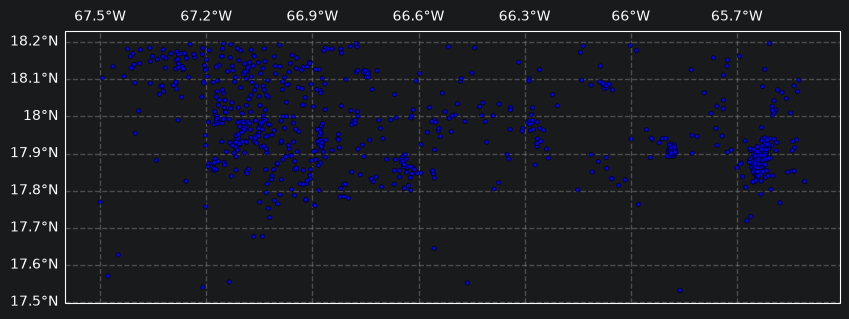

In [4]:
fig = plt.figure(figsize=(10, 10), linewidth=1)
ax = cat.plot_in_space(
    dot_smallest=0.1,
    dot_largest=10,
    dot_interpolation_power=0,
    dot_labels=False)

plt.show()

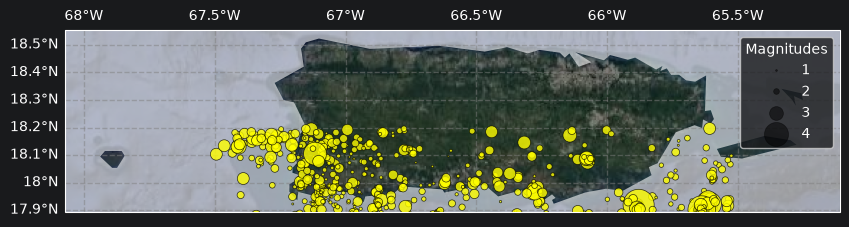

In [5]:
fig = plt.figure(figsize=(10, 10), linewidth=1)
ax = cat.plot_in_space(
    resolution='10m',
    include_map=True,
    country='Puerto Rico',
    dot_smallest=1,
    dot_largest=500,
    dot_interpolation_power=3,
    dot_labels=[1,2,3,4],
    color_dots = 'yellow')

plt.show()

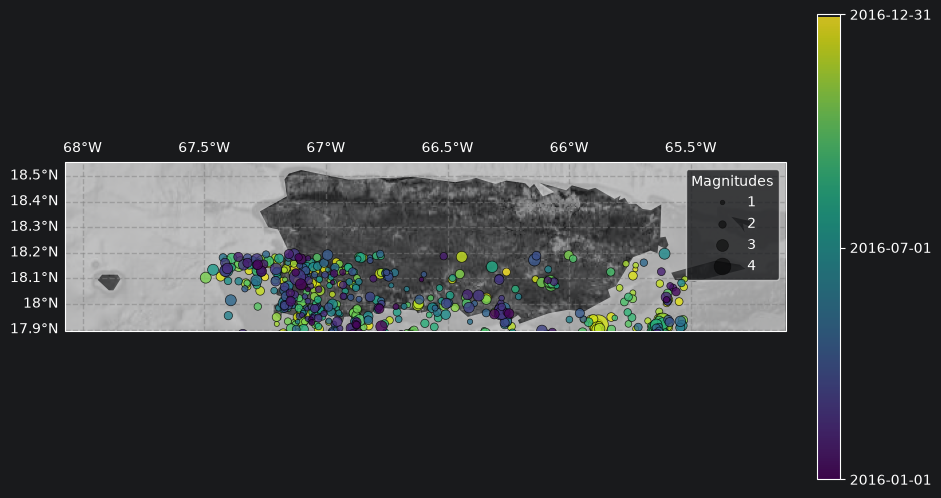

In [6]:
fig = plt.figure(figsize=(10, 10), linewidth=1)

ax = cat.plot_in_space(
    resolution='10m',
    include_map=True,
    country='Puerto Rico',
    color_dots=mdates.date2num(cat.time),
    color_map='Greys_r',
    dot_labels=[1, 2, 3, 4]
)

cbar = plt.colorbar(ax.collections[1], ax=ax, orientation='vertical', fraction=0.03, pad=0.04)


date_ticks = ["2016-01-01", "2016-07-01", "2016-12-31"]
date_ticks_num = mdates.date2num(date_ticks)
cbar.set_ticks(date_ticks_num)
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.show()

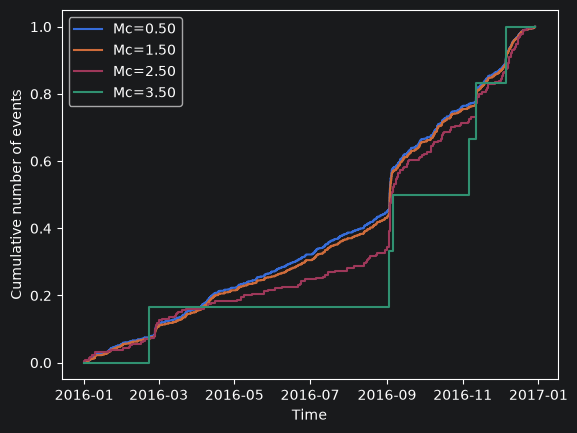

In [7]:
target_magnitudes = np.arange(0.5, 4.0, 1.0)

ax = cat.plot_cum_count(mcs=target_magnitudes)

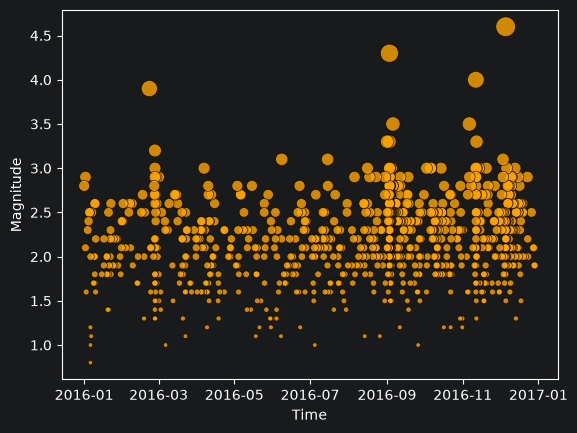

In [8]:
ax = cat.plot_mags_in_time(color_dots='orange')

Legend added to the plot.


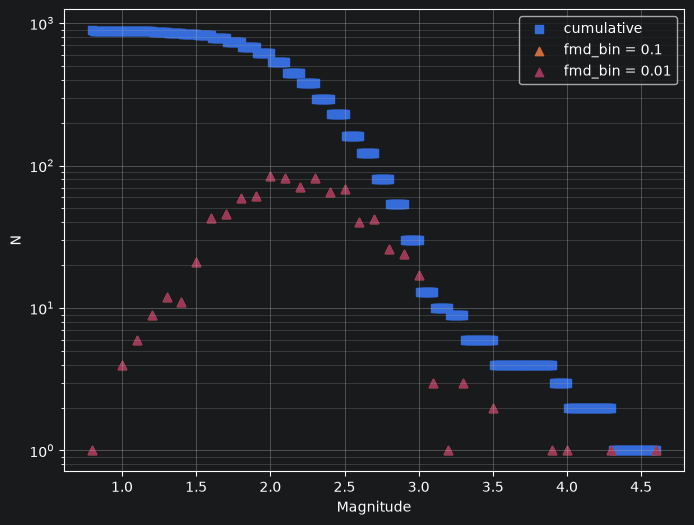

In [9]:
cat.bin_magnitudes(delta_m=0.01, inplace=True)

ax = plt.subplots(figsize=(8, 6))[1]

cat.plot_cum_fmd(ax=ax)

cat.plot_fmd(fmd_bin=0.1, ax=ax, grid=True, label='fmd_bin = 0.1')
cat.plot_fmd(fmd_bin=0.01, ax=ax, grid=True, label='fmd_bin = 0.01')

plt.show()

In [10]:
mc_maxc, _= cat.estimate_mc_maxc(fmd_bin=0.1)

print(f'Estimated Mc using MAXC: {mc_maxc}')
print(f'Mc (currently set catalog attribute): {cat.mc}')

Estimated Mc using MAXC: 2.2
Mc (currently set catalog attribute): 2.2


In [18]:
mc_stab, _ = cat.estimate_mc_b_stability(stop_when_passed=True)

print(f'Estimated Mc using MBS: {mc_stab}')

print(f'Mc (currently set catalog attribute): {cat.mc}')

return_vals: {'best_b_value': np.float64(1.6132402087411863), 'mcs_tested': [0.8, 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 1.0, 1.01, 1.02, 1.03, 1.04, 1.05, 1.06, 1.07, 1.08, 1.09, 1.1, 1.11, 1.12, 1.13, 1.14, 1.15, 1.16, 1.17, 1.18, 1.19, 1.2, 1.21, 1.22, 1.23, 1.24, 1.25, 1.26, 1.27, 1.28, 1.29, 1.3, 1.31, 1.32, 1.33, 1.34, 1.35, 1.36, 1.37, 1.38, 1.39, 1.4, 1.41, 1.42, 1.43, 1.44, 1.45, 1.46, 1.47, 1.48, 1.49, 1.5, 1.51, 1.52, 1.53, 1.54, 1.55, 1.56, 1.57, 1.58, 1.59, 1.6, 1.61, 1.62, 1.63, 1.64, 1.65, 1.66, 1.67, 1.68, 1.69, 1.7, 1.71, 1.72, 1.73, 1.74, 1.75, 1.76, 1.77, 1.78, 1.79, 1.8, 1.81, 1.82, 1.83, 1.84, 1.85, 1.86, 1.87, 1.88, 1.89, 1.9, 1.91, 1.92, 1.93, 1.94, 1.95, 1.96, 1.97, 1.98, 1.99, 2.0, 2.01, 2.02, 2.03, 2.04, 2.05, 2.06, 2.07, 2.08, 2.09, 2.1, 2.11, 2.12, 2.13, 2.14, 2.15, 2.16, 2.17, 2.18, 2.19, 2.2, 2.21, 2.22, 2.23, 2.24, 2.25, 2.26, 2.27, 2.28, 2.29, 2.3, 2.31, 2.32, 2.33, 2.34, 2.35, 2.3

In [27]:
mc_kstest, dict = cat.estimate_mc_ks(
   mcs_test=np.arange(1.0, 3.0, 0.1),
    p_value_pass=0.0000000000000000000000000000000000000000000000000000000000000001,
)

print(f"First Mc to pass the KS test: {mc_kstest:.2f}")
print(f"Associated beta value: {dict['best_b_value']:.2f}")


print(f'Mc (currently set catalog attribute): {cat.mc:.2f}')

TypeError: unsupported format string passed to NoneType.__format__

Legend added to the plot.


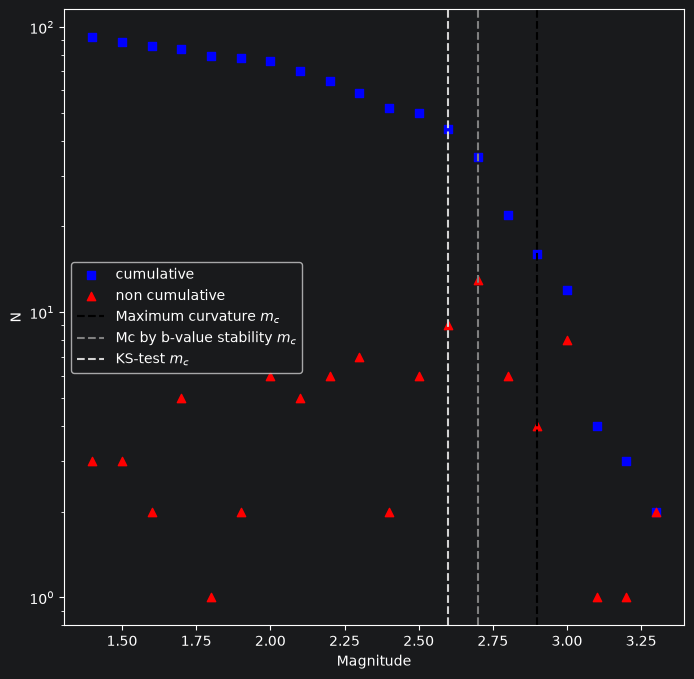

In [55]:
ax = plt.subplots(figsize=(8, 8))[1]

cat.plot_cum_fmd(fmd_bin=0.1, ax=ax, color='blue')
cat.plot_fmd(fmd_bin=0.1, ax=ax, color='red')

plt.axvline(mc_maxc, color='black', linestyle='--', label='Maximum curvature $m_c$')
plt.axvline(mc_stab, color='grey', linestyle='--', label='Mc by b-value stability $m_c$')
plt.axvline(mc_kstest, color='lightgrey', linestyle='--', label='KS-test $m_c$')

plt.legend()
plt.show()

In [56]:
b_estimator = cat.estimate_b()

print('Classical b-value', round(b_estimator.b_value,3))
print('Standard deviation', round(b_estimator.std,2))
print('Number of events used', b_estimator.n)

Classical b-value 1.987
Standard deviation 0.26
Number of events used 44


Legend added to the plot.


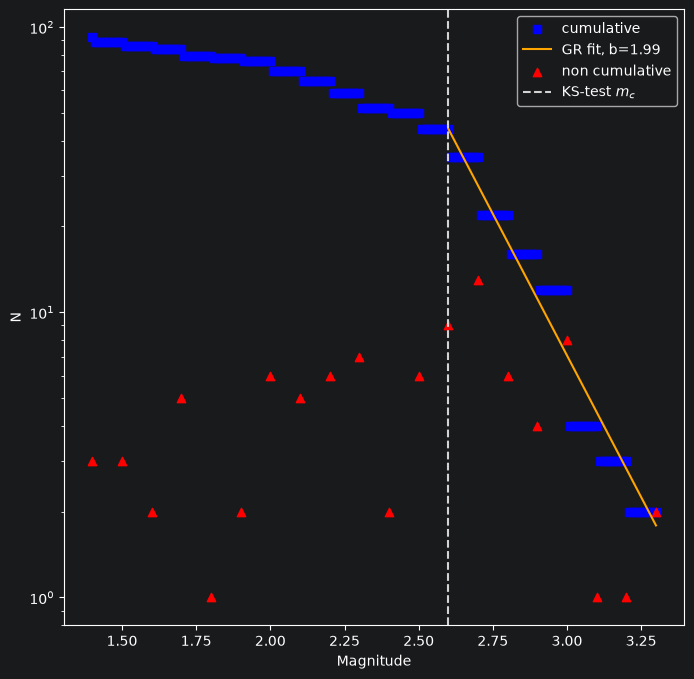

In [57]:
ax = plt.subplots(figsize=(8, 8))[1]
cat.plot_cum_fmd(color='blue',ax=ax, color_line = 'orange')
cat.plot_fmd(fmd_bin=0.1, ax=ax, color='red')

plt.axvline(mc_kstest, color='lightgrey', linestyle='--', label='KS-test $m_c$')
plt.legend()
plt.show()

In [58]:
from seismostats.analysis import BPositiveBValueEstimator
b_estimator = cat.estimate_b(method =BPositiveBValueEstimator)
print("b-positive:",round(cat.b_value,2))

b-positive: 1.62


<Axes: xlabel='Completeness magnitude $m_c$', ylabel='b-value'>

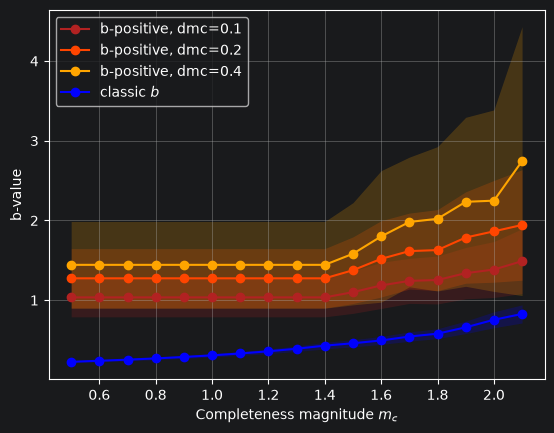

In [61]:
from seismostats.analysis import ClassicBValueEstimator, BPositiveBValueEstimator

mcs = np.arange(0.5, 2.2, 0.1)
ax = cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.1, color='firebrick', label='b-positive, dmc=0.1')
cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.2, ax=ax,  color='orangered', label='b-positive, dmc=0.2')
cat.plot_mc_vs_b(mcs, b_method=BPositiveBValueEstimator, dmc=0.4, ax=ax,  color='orange', label='b-positive, dmc=0.4')

cat.plot_mc_vs_b(mcs, b_method=ClassicBValueEstimator, ax =ax, color='blue', label='classic $b$')

Text(0.5, 0, 'Time')

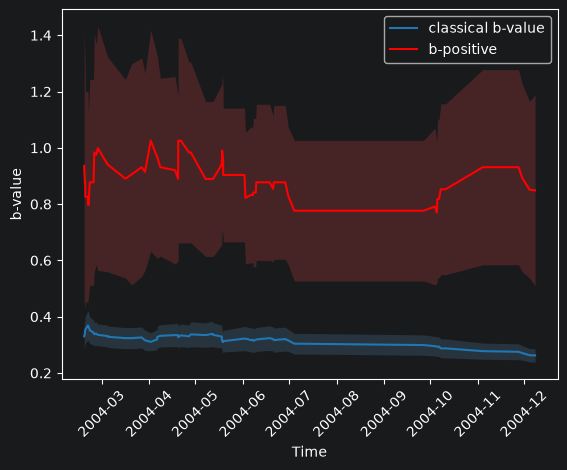

In [68]:
from seismostats.analysis import b_significant_1D
from seismostats.plots import plot_b_series_constant_nm, plot_b_significant_1D

mc = 1
delta_m = cat.delta_m
times = cat.time
mags = cat.magnitude
n_m = 30

ax = plot_b_series_constant_nm(mags, delta_m, mc, times, n_m=n_m, x_variable=times, color='#1f77b4', plot_technique='right', label='classical b-value')

ax = plot_b_series_constant_nm(mags, delta_m, mc, times, n_m=n_m, x_variable=times, color='red', plot_technique='right', label='b-positive', ax=ax, method=BPositiveBValueEstimator)

_ = plt.xticks(rotation=45)
ax.set_xlabel('Time')

In [69]:
p_threshold = 0.05
p, mac, mu_mac, std_mac = b_significant_1D(mags, mc, delta_m, times, n_m, x_variable=times, method= BPositiveBValueEstimator)
print('The p-value of a constant b-value hypothesis is {:.2f}'.format(p))

print('This is significantly larger than our threshold of {:.2f}. Therefore, we cannot reject the null-hypothesis'.format(p_threshold))

The p-value of a constant b-value hypothesis is nan
This is significantly larger than our threshold of 0.05. Therefore, we cannot reject the null-hypothesis


C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\analysis\b_significant.py:402: UserWarning: The number of non overlapping b-value estimates is less than15. The normality assumption of the autocorrelation might not be valid.
  warnings.warn(


C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\analysis\bvalue\base.py:119: UserWarning: No magnitudes in the lowest magnitude bin are present.Check if mc is chosen correctly.
  warnings.warn(
C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\plots\statistical.py:330: UserWarning: Not enough events to estimate significance.
  warnings.warn("Not enough events to estimate significance.")
C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\seismostats\analysis\bvalue\utils.py:99: RuntimeWarning: invalid value encountered in scalar divide
  np.log(10) * b**2 * std_mags / np.sqrt(len_mags - 1)
C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:588: RuntimeWarning: Mean of empty slice
  avg = a.mean(axis, **keepdims_kw)
C:\Users\leyma\PycharmProjects\PythonProject\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in 

<Axes: xlabel='$n_m$', ylabel='MAC'>

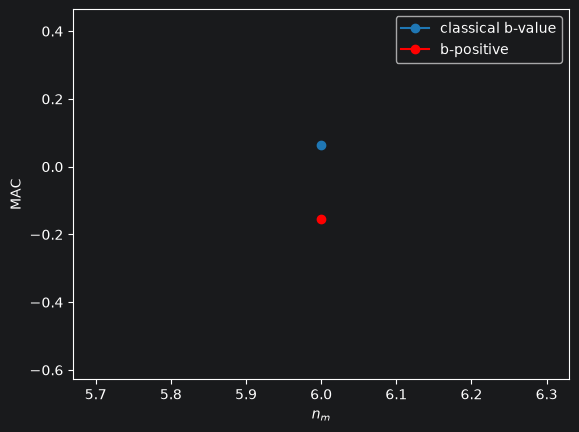

In [70]:
srt = np.argsort(times)
mags = mags[srt]
times = times[srt]

ax = plot_b_significant_1D(
    mags, mc, delta_m, times, x_variable=times, color = '#1f77b4', label='classical b-value')

plot_b_significant_1D(
    mags, mc, delta_m,  times, x_variable=times, method=BPositiveBValueEstimator, color = 'red', ax = ax, label='b-positive')


In [71]:
from seismostats.utils import simulate_magnitudes_binned


n = 500
b_value = 1.5
delta_m = 0.05
mc = 3
dmc = 0.3

mags = simulate_magnitudes_binned(n, b_value, mc, delta_m)
cat = pd.DataFrame({'magnitude': mags})
cat = Catalog(cat)
cat.delta_m = delta_m
cat.mc = mc


cat.estimate_b()
print('Estimated b-value of the synthetic catalog:', round(cat.b_value,2))

Estimated b-value of the synthetic catalog: 1.48


Legend added to the plot.


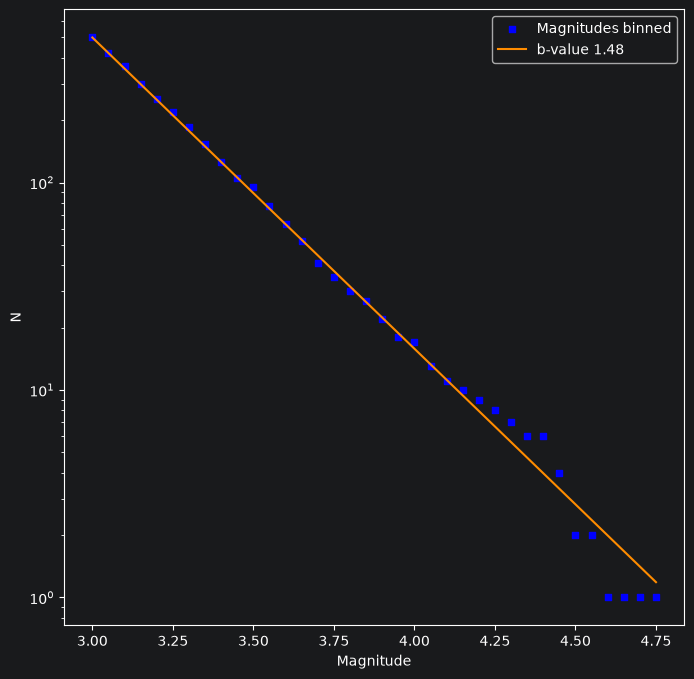

In [72]:
ax = plt.subplots(figsize=(8, 8))[1]

cat.plot_cum_fmd(ax=ax, b_value=b_value,
             color='blue', color_line = 'darkorange', label='Magnitudes binned', label_line = f'b-value {cat.b_value:.2f}', size=20)

plt.show()

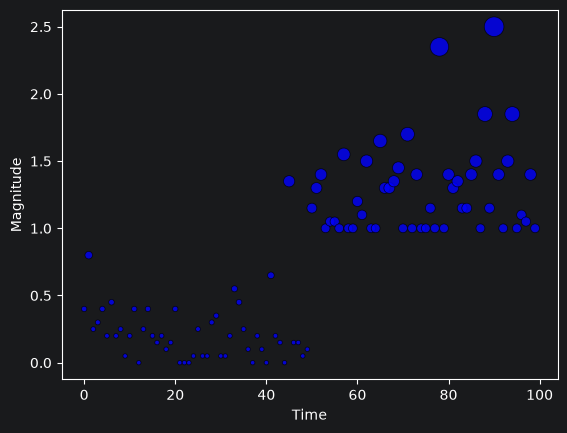

In [73]:
from seismostats.utils import simulate_magnitudes_binned
from seismostats.plots import plot_mags_in_time
n = 100
b_value = 1.5
delta_m = 0.05
mc = np.zeros(n)
mc[n//2:] = 1
mags = simulate_magnitudes_binned(n, b_value, mc, delta_m)
ax = plot_mags_in_time(np.arange(len(mags)), mags)